In [1]:
import pandas as pd

df = pd.read_excel("Telco_customer_churn.xlsx")
print(df.shape)
print(list(df.columns))
df.head()

(7043, 33)
['CustomerID', 'Count', 'Country', 'State', 'City', 'Zip Code', 'Lat Long', 'Latitude', 'Longitude', 'Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method', 'Monthly Charges', 'Total Charges', 'Churn Label', 'Churn Value', 'Churn Score', 'CLTV', 'Churn Reason']


,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [2]:
for c in df.columns:
    print(c, "|", df[c].dtype)

CustomerID | str
Count | int64
Country | str
State | str
City | str
Zip Code | int64
Lat Long | str
Latitude | float64
Longitude | float64
Gender | str
Senior Citizen | str
Partner | str
Dependents | str
Tenure Months | int64
Phone Service | str
Multiple Lines | str
Internet Service | str
Online Security | str
Online Backup | str
Device Protection | str
Tech Support | str
Streaming TV | str
Streaming Movies | str
Contract | str
Paperless Billing | str
Payment Method | str
Monthly Charges | float64
Total Charges | object
Churn Label | str
Churn Value | int64
Churn Score | int64
CLTV | int64
Churn Reason | str


In [3]:
df.columns = df.columns.str.strip()

# SQL aur Power BI ke liye poora data bachake rakho
df_raw = df.copy()

# Total Charges text hai, number banao
df["Total Charges"] = pd.to_numeric(df["Total Charges"], errors="coerce")
print("Blank rows:", df["Total Charges"].isna().sum())   # 11 aana chahiye
df = df.dropna(subset=["Total Charges"]).copy()

# Target column
df["Churn"] = df["Churn Label"].map({"Yes": 1, "No": 0})

# Faltu aur leakage wale columns hatao
drop_cols = ["CustomerID", "Count", "Country", "State", "City", "Zip Code",
             "Lat Long", "Latitude", "Longitude",
             "Churn Label", "Churn Value", "Churn Score", "CLTV", "Churn Reason"]
df = df.drop(columns=drop_cols)

print(df.shape)                                          # (7032, 20)
print("Churn rate:", round(df["Churn"].mean() * 100, 2), "%")   # ~26.58 %

Blank rows: 11
(7032, 20)
Churn rate: 26.58 %


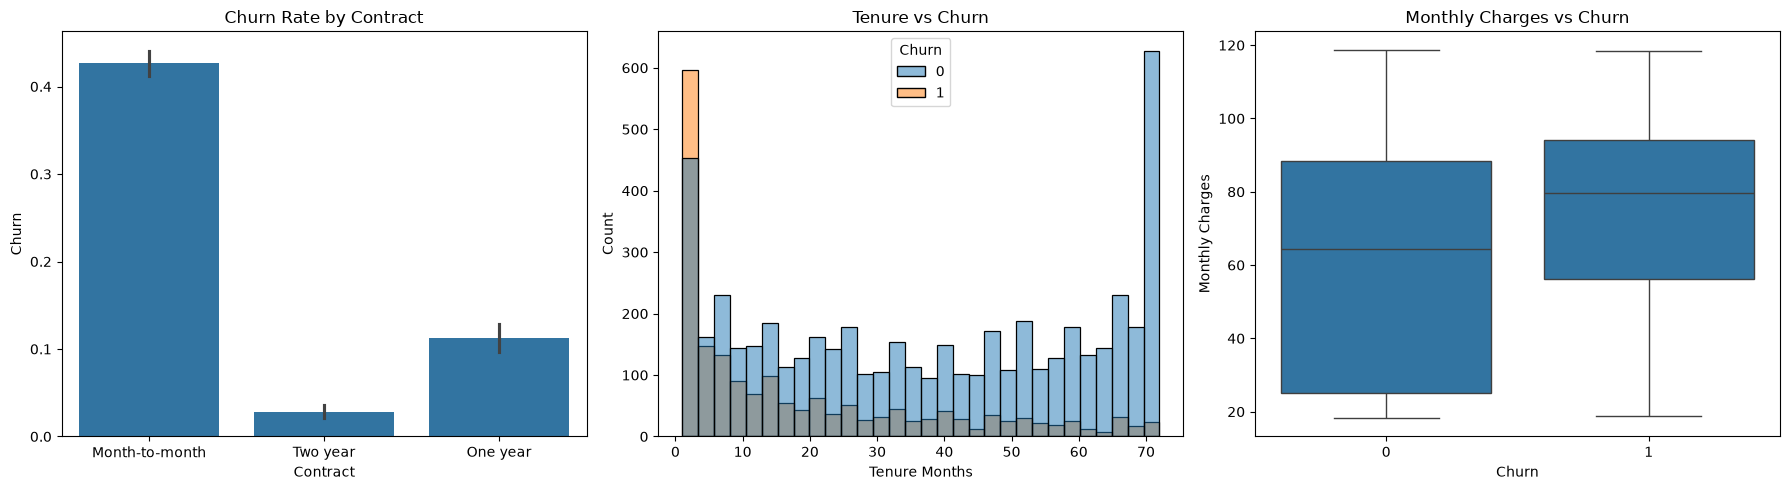

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.barplot(data=df, x="Contract", y="Churn", ax=axes[0])
axes[0].set_title("Churn Rate by Contract")

sns.histplot(data=df, x="Tenure Months", hue="Churn", bins=30, ax=axes[1])
axes[1].set_title("Tenure vs Churn")

sns.boxplot(data=df, x="Churn", y="Monthly Charges", ax=axes[2])
axes[2].set_title("Monthly Charges vs Churn")

plt.tight_layout()
plt.savefig("eda_charts.png", dpi=150)
plt.show()

In [5]:
from sklearn.model_selection import train_test_split

df_model = pd.get_dummies(df, drop_first=True)
X = df_model.drop("Churn", axis=1)
y = df_model["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)

(5625, 30) (1407, 30)


In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score
from xgboost import XGBClassifier

neg, pos = (y_train == 0).sum(), (y_train == 1).sum()

models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, class_weight="balanced")),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, class_weight="balanced", random_state=42),
    "XGBoost": XGBClassifier(
        n_estimators=300, learning_rate=0.05, max_depth=4,
        scale_pos_weight=neg/pos, eval_metric="logloss", random_state=42),
}

rows = []
for name, m in models.items():
    m.fit(X_train, y_train)
    pred = m.predict(X_test)
    rows.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, pred) * 100, 2),
        "Precision": round(precision_score(y_test, pred) * 100, 2),
        "Recall": round(recall_score(y_test, pred) * 100, 2),
        "F1": round(f1_score(y_test, pred) * 100, 2),
    })

results = pd.DataFrame(rows).sort_values("Recall", ascending=False)
results

,Model,Accuracy,Precision,Recall,F1
2,XGBoost,74.13,50.86,78.88,61.84
0,Logistic Regression,72.92,49.41,78.61,60.68
1,Random Forest,77.47,56.13,69.79,62.22


In [7]:
best = models["XGBoost"]

out = df.copy()
out["Churn_Probability"] = best.predict_proba(X)[:, 1]
out["Predicted_Churn"] = (out["Churn_Probability"] >= 0.5).astype(int)

out.to_csv("churn_predictions.csv", index=False)
print(out.shape)
out[["Churn", "Churn_Probability", "Predicted_Churn"]].head()

(7032, 22)


,Churn,Churn_Probability,Predicted_Churn
0,1,0.648258,1
1,1,0.660359,1
2,1,0.870705,1
3,1,0.397685,0
4,1,0.465949,0


In [8]:
final = df_raw.loc[out.index].copy()
final["Total Charges"] = pd.to_numeric(final["Total Charges"])
final["Churn_Probability"] = out["Churn_Probability"]
final["Predicted_Churn"] = out["Predicted_Churn"]

# check: dono same hone chahiye
print((final["Churn Value"] == out["Churn"]).all())

final.to_csv("churn_predictions.csv", index=False)
print(final.shape)

True
(7032, 35)


In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score

neg, pos = (y_train == 0).sum(), (y_train == 1).sum()

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42),
    "XGBoost": XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                             scale_pos_weight=neg/pos, random_state=42, eval_metric="logloss"),
}

rows = []
for name, m in models.items():
    m.fit(X_train, y_train)
    pred = m.predict(X_test)
    rows.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, pred) * 100, 1),
        "Precision": round(precision_score(y_test, pred) * 100, 1),
        "Recall": round(recall_score(y_test, pred) * 100, 1),
        "F1": round(f1_score(y_test, pred) * 100, 1),
    })

pd.DataFrame(rows)

c:\Users\SHIVA\shiva_jadaun\week1\churnsense\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,73.0,49.5,78.6,60.7
1,Random Forest,77.5,56.1,69.8,62.2
2,XGBoost,74.1,50.9,78.9,61.8


In [10]:
import sqlite3

conn = sqlite3.connect("churn.db")
final = pd.read_csv("churn_predictions.csv")
final.columns = final.columns.str.replace(" ", "_")
final.to_sql("customers", conn, if_exists="replace", index=False)

pd.read_sql("SELECT COUNT(*) AS total FROM customers", conn)

,total
0,7032


In [11]:
q1 = """
SELECT Contract,
       COUNT(*) AS customers,
       SUM(Churn_Value) AS churned,
       ROUND(100.0 * SUM(Churn_Value) / COUNT(*), 1) AS churn_rate_pct
FROM customers
GROUP BY Contract
ORDER BY churn_rate_pct DESC
"""
pd.read_sql(q1, conn)

,Contract,customers,churned,churn_rate_pct
0,Month-to-month,3875,1655,42.7
1,One year,1472,166,11.3
2,Two year,1685,48,2.8


In [12]:
q2 = """
SELECT CASE
         WHEN Tenure_Months <= 12 THEN '0-12 months'
         WHEN Tenure_Months <= 24 THEN '13-24 months'
         ELSE '25+ months'
       END AS tenure_bucket,
       COUNT(*) AS customers,
       ROUND(100.0 * (COUNT(*) - SUM(Churn_Value)) / COUNT(*), 1) AS retention_pct
FROM customers
GROUP BY tenure_bucket
ORDER BY MIN(Tenure_Months)
"""
pd.read_sql(q2, conn)

,tenure_bucket,customers,retention_pct
0,0-12 months,2175,52.3
1,13-24 months,1024,71.3
2,25+ months,3833,86.0


In [13]:
q3 = """
SELECT COUNT(*) AS likely_churners,
       ROUND(SUM(Monthly_Charges), 2) AS monthly_revenue_at_risk,
       ROUND(SUM(Monthly_Charges) * 12, 2) AS yearly_revenue_at_risk
FROM customers
WHERE Predicted_Churn = 1 AND Churn_Value = 0
"""
pd.read_sql(q3, conn)

,likely_churners,monthly_revenue_at_risk,yearly_revenue_at_risk
0,1196,87218.9,1046626.8
